# One-controller NARX study: LSO navigation, halo station-keeping and Gateway tracking

Only the **halo observer** performs maneuvers, guided by its LSO-derived joint EKF navigation estimates. Gateway is a prescribed periodic 9:2 NRHO tracking target and receives **no commanded Δv**. The Gateway reference passes a numerical closure check in the same idealized Earth–Moon CR3BP used by the observer. Gateway position/velocity tracking accuracy remains an independent outcome, never a control label.

**Experiment sequence:** (1) generate short independent STM teacher-training/validation/test arcs, (2) fit and score NARX imitation, (3) execute paired **365-day** uncontrolled/STM/NARX closed-loop rollouts with matched initial states and epoch-indexed optical noise, and (4) compare maintenance success, cumulative observer Δv, and Gateway tracking. Stages 1–2 execute by default. The expensive 365-day rollout is an explicit opt-in; it can also be run using `python scripts/run_one_year_study.py --days 365 --arcs 5`.

The learned model in this repository uses gradient-boosted predictors on lagged autoregressive features (NARX-*inspired*, not a recurrent NARX neural network). Neither offline label agreement nor a successful short test is proof of one-year learned-controller performance.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository checkout")
preview = ROOT / "results/narx_closed_loop_preview"
full = ROOT / "results/narx_closed_loop"
dataset_dir = full if (full / "test.npz").exists() else preview
if not (dataset_dir / "test.npz").exists():
    display(Markdown("**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook."))
else:
    display(Markdown(f"Reading **{dataset_dir.relative_to(ROOT)}**. " + ("Full Monte Carlo dataset." if dataset_dir == full else "Small notebook preview, **one arc per split**; do not interpret as Monte Carlo validation.")))


**No closed-loop results found.** Run the main notebook or `python scripts/run_closed_loop_narx.py`, then rerun this notebook.

## Observer-only NARX guidance equations

The LSO network provides noisy angles $\boldsymbol z_{\mathrm{LSO},k}=h(\boldsymbol x_{H,k})+\boldsymbol\nu_k$. The joint EKF produces the observer estimate $\hat{\boldsymbol x}_{H,k}$ and covariance $P_{H,k}$, so the model never receives simulated truth.

Define observer departure $\hat{\boldsymbol e}_{H,k}=\hat{\boldsymbol x}_{H,k}-\boldsymbol x_H^*(t_k)$ in the chosen rotating-frame error convention. A causal NARX-inspired predictor uses lagged estimates and past executed observer controls:

$$
(\hat m_k,\widehat{\Delta\boldsymbol v}_{H,k},\hat j_k)
=F_\theta\bigl(\hat{\boldsymbol e}_{H,k:k-L+1},
\Delta\boldsymbol v_{H,k-1:k-L},\sin\phi_k,\cos\phi_k,
P_{H,k},\mathrm{LSO\ visibility}_k,\mathrm{Gateway\ tracking\ quality}_k\bigr).
$$

This baseline uses gradient-boosted models on lagged features, not a recurrent neural network. The label generator uses STM-based observer-only corrections and nonlinear feasibility checks. The model is fitted only to observer maneuver labels. Gateway has **no** maneuver targets or trained control head.

Gateway tracking errors are measured separately against the prescribed target trajectory. These results measure an offline teacher-imitation model; demonstration of one-year closed-loop performance with learned commands requires a separate rollout.

## Step 1 — Generate short-arc STM teacher data

The short, independent training/validation/test Monte Carlo trajectories provide feasible observer maneuver labels and actual applied-control histories from **noisy LSO-driven EKF estimates**. The phase-aware demonstration uses noisily sampled navigation proxies; the closed-loop dataset uses the optical EKF. Neither should be confused with the year-long policy comparison.

The one-year experiment is deliberately separate from training to avoid test-trajectory leakage.

In [2]:
from halo_tracking.study import load_config
from halo_tracking.narx_dataset import generate_phase_aware_dataset
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset

cfg = load_config()
phase_dir = ROOT / "results/narx_phase_aware"
closed_dir = ROOT / "results/narx_closed_loop"

print("Generating phase-aware, label-only Monte Carlo arcs...", flush=True)
phase_summary = generate_phase_aware_dataset(cfg, phase_dir)
print(json.dumps(phase_summary, indent=2), flush=True)

print("Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...", flush=True)
closed_summary = generate_closed_loop_dataset(cfg, closed_dir)
print(json.dumps(closed_summary, indent=2), flush=True)
dataset_dir = closed_dir
print("Saved ensembles:", phase_dir, closed_dir, sep="\n")

Generating phase-aware, label-only Monte Carlo arcs...


{
  "training": {
    "arcs": 20,
    "decisions": 340,
    "observer_valid": 340,
    "gateway_valid": 0
  },
  "validation": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 0
  },
  "test": {
    "arcs": 5,
    "decisions": 85,
    "observer_valid": 85,
    "gateway_valid": 0
  }
}


Generating closed-loop Monte Carlo arcs with applied maneuvers and tracking...


{
  "training": {
    "arcs": 20,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.3382352941176471,
    "gateway_velocity_within_limit_fraction": 0.8,
    "gateway_both_tracking_limits_fraction": 0.3382352941176471,
    "observer_total_delta_v_m_s": 36.256332683209024,
    "gateway_total_delta_v_m_s": 0.0
  },
  "validation": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4117647058823529,
    "gateway_velocity_within_limit_fraction": 0.7764705882352941,
    "gateway_both_tracking_limits_fraction": 0.4117647058823529,
    "observer_total_delta_v_m_s": 8.927679759034953,
    "gateway_total_delta_v_m_s": 0.0
  },
  "test": {
    "arcs": 5,
    "decision_epochs_per_arc": 17,
    "gateway_position_within_100m_fraction": 0.4,
    "gateway_velocity_within_limit_fraction": 0.8117647058823529,
    "gateway_both_tracking_limits_fraction": 0.4,
    "observer_total_delta_v_m_s": 7.211541027843701,
    "gateway_t

Saved ensembles:
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_phase_aware
/home/runner/work/Halo_Orbit_Tracking/Halo_Orbit_Tracking/results/narx_closed_loop


In [3]:
for label, folder in (("Phase-aware (labels only)", phase_dir), ("Closed-loop (applied burns)", closed_dir)):
    print("\n" + label)
    for split in ("training", "validation", "test"):
        with np.load(folder / f"{split}.npz") as d:
            names = set(d.files)
            key = "gateway_maneuver_required"
            arcs = int(d[key].shape[0]) if key in names else "n/a"
            decisions = int(d[key].size) if key in names else "n/a"
            triggered = int(d[key].sum()) if key in names else "n/a"
            feasible = int((d[key] & d["gateway_maneuver_valid"]).sum()) if key in names and "gateway_maneuver_valid" in names else "n/a"
            print(f"  {split}: arcs={arcs}, decisions={decisions}, Gateway requested={triggered}, feasible requested={feasible}")
print("\nNo held-out arc is used for model fitting.")


Phase-aware (labels only)
  training: arcs=20, decisions=340, Gateway requested=0, feasible requested=0
  validation: arcs=5, decisions=85, Gateway requested=0, feasible requested=0
  test: arcs=5, decisions=85, Gateway requested=0, feasible requested=0

Closed-loop (applied burns)
  training: arcs=20, decisions=340, Gateway requested=0, feasible requested=0
  validation: arcs=5, decisions=85, Gateway requested=0, feasible requested=0
  test: arcs=5, decisions=85, Gateway requested=0, feasible requested=0

No held-out arc is used for model fitting.


## Step 2 — Fit and evaluate the observer-only teacher-imitation baseline

Evaluate the NARX-inspired classifier, observer Δv regressor, and burn-delay class predictor on held-out short arcs. These are offline teacher-imitation scores, **not** one-year station-keeping outcomes. The trained rollout bundle below fits only the training split and is subsequently frozen.

In [4]:
from halo_tracking.two_stage_narx import evaluate_two_stage

metrics_dir = ROOT / "results/narx_two_stage"
report = evaluate_two_stage(closed_dir, metrics_dir, cfg)
print("Trained on MC training arcs and evaluated on held-out validation/test arcs.")
print(json.dumps(report, indent=2))
metrics_path = metrics_dir / "metrics.json"

Trained on MC training arcs and evaluated on held-out validation/test arcs.
{
  "observer": {
    "status": "evaluated",
    "training_decisions": 260,
    "training_triggered": 41,
    "training_feasible_triggered": 41,
    "validation": {
      "evaluated_decisions": 65,
      "positive_rate": 0.12307692307692308,
      "maneuver_precision": 0.8333333333333334,
      "maneuver_recall": 0.625,
      "maneuver_f1": 0.7142857142857143,
      "confusion_matrix_true_rows": [
        [
          56,
          1
        ],
        [
          3,
          5
        ]
      ],
      "feasible_burn_examples": 8,
      "delta_v_rmse_m_s": 0.25333743500483163,
      "burn_delay_class_accuracy_teacher_forced": 0.75
    },
    "test": {
      "evaluated_decisions": 65,
      "positive_rate": 0.13846153846153847,
      "maneuver_precision": 0.6666666666666666,
      "maneuver_recall": 0.4444444444444444,
      "maneuver_f1": 0.5333333333333333,
      "confusion_matrix_true_rows": [
        [
     

## Gateway tracking after maneuvers

Position and velocity errors are calculated from the estimated and simulated true Gateway states:

$$
e_r(t)=\|\hat{\mathbf r}_{G}(t)-\mathbf r_G(t)\|,\qquad
e_v(t)=\|\hat{\mathbf v}_{G}(t)-\mathbf v_G(t)\|.
$$

The 100 m and 0.01 m/s limits must be satisfied **at the same time**. The first plot shows error histories; the table reports how often both limits are met. A successful result requires consistent performance across independent Monte Carlo realizations, not a single favorable trajectory.

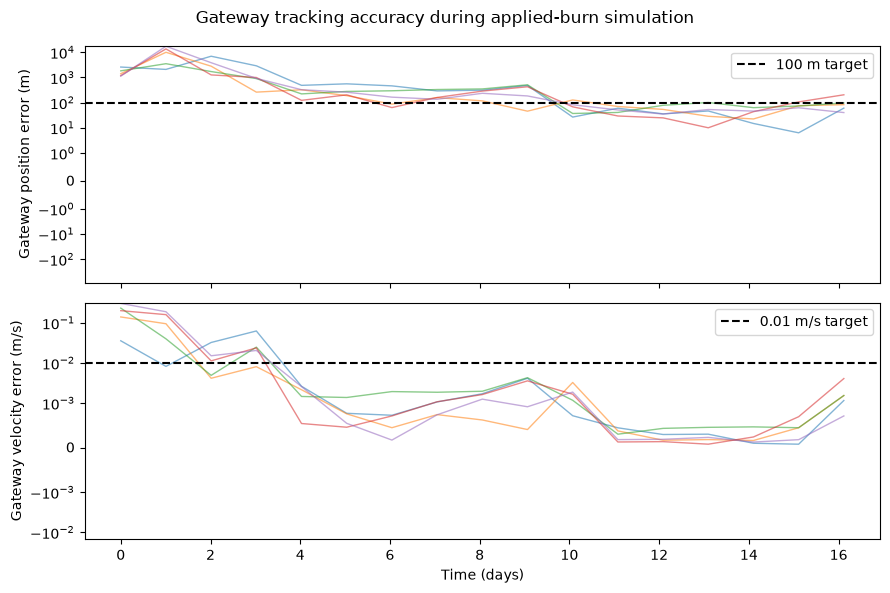

**Held-out test:** 5 episode(s). Position within 100 m: **40.0%** of decision epochs. Velocity within 0.01 m/s: **81.2%**. **Both limits simultaneously: 40.0%**. These are tracking-error metrics, not reference-departure metrics.

In [5]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        t = np.array(d["decision_times_tu"]) * 375190.25852 / 86400
        p = np.array(d["gateway_tracking_position_error_km"])
        v = np.array(d["gateway_tracking_velocity_error_m_s"])
        both = (p <= 0.1) & (v <= 0.01)
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
        for i in range(min(len(p), 8)):
            ax1.plot(t, p[i]*1000, alpha=.55, linewidth=1)
            ax2.plot(t, v[i], alpha=.55, linewidth=1)
        ax1.axhline(100, linestyle="--", color="black", label="100 m target")
        ax2.axhline(.01, linestyle="--", color="black", label="0.01 m/s target")
        ax1.set_ylabel("Gateway position error (m)")
        ax2.set_ylabel("Gateway velocity error (m/s)")
        ax2.set_xlabel("Time (days)")
        ax1.legend()
        ax2.legend()
        ax1.set_yscale("symlog", linthresh=1)
        ax2.set_yscale("symlog", linthresh=.001)
        fig.suptitle("Gateway tracking accuracy during applied-burn simulation")
        plt.tight_layout()
        plt.show()
        display(Markdown(
            f"**Held-out test:** {len(p)} episode(s). Position within 100 m: **{100*np.mean(p<=.1):.1f}%** of decision epochs. "
            f"Velocity within 0.01 m/s: **{100*np.mean(v<=.01):.1f}%**. "
            f"**Both limits simultaneously: {100*np.mean(both):.1f}%**. "
            "These are tracking-error metrics, not reference-departure metrics."
        ))

## Observer maneuver labels and executed burns

Only the halo observer receives burn requests, feasible STM corrections, or applied impulses. Gateway is an unactuated tracking target. No Gateway maneuver totals or classifications should be interpreted as outcomes.

In [6]:
if (dataset_dir / "test.npz").exists():
    with np.load(dataset_dir / "test.npz") as d:
        lines = ["| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |", "|---|---:|---:|---:|---:|---:|"]
        for name in ("observer",):
            requested = np.asarray(d[name + "_maneuver_required"], dtype=bool)
            valid = np.asarray(d[name + "_maneuver_valid"], dtype=bool)
            applied = np.linalg.norm(d[name + "_applied_delta_v_rotating_m_s"], axis=-1) > 0
            lines.append(f"| {name.title()} | {requested.size} | {requested.sum()} | {(requested & valid).sum()} | {(requested & ~valid).sum()} | {applied.sum()} |")
        display(Markdown("\n".join(lines)))
        display(Markdown("The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs."))

| Spacecraft | Decisions | Requested | Feasible requested | Rejected requested | Nonzero applied-burn records |
|---|---:|---:|---:|---:|---:|
| Observer | 85 | 14 | 14 | 0 | 14 |

The applied-burn count reflects **saved nonzero records**, not necessarily distinct commands when multiple impulses occur between decision epochs.

## Observer maneuver learning results

Held-out observer precision/recall/F1, Δv RMSE, and teacher-forced delay accuracy are offline imitation metrics, not station-keeping success. Gateway has no maneuver predictor; its optical tracking results are above.

In [7]:
metrics_path = ROOT / "results/narx_two_stage/metrics.json"
if metrics_path.exists():
    metrics = json.loads(metrics_path.read_text())
    lines = ["| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |", "|---|---|---:|---:|---:|---:|---:|"]
    for name, result in metrics.items():
        if name != "observer":
            continue
        for split in ("validation", "test"):
            m = result.get(split)
            if m is None:
                continue
            rmse = "N/A" if m["delta_v_rmse_m_s"] is None else f'{m["delta_v_rmse_m_s"]:.5f}'
            delay = "N/A" if m["burn_delay_class_accuracy_teacher_forced"] is None else f'{100*m["burn_delay_class_accuracy_teacher_forced"]:.1f}%'
            lines.append(f'| {name.title()} | {split} | {m["maneuver_f1"]:.3f} | {m["maneuver_precision"]:.3f} | {m["maneuver_recall"]:.3f} | {rmse} | {delay} |')
    display(Markdown("\n".join(lines)))
else:
    display(Markdown("**Learned-model scores have not been generated in this checkout.** Run `python scripts/run_two_stage_narx.py` to generate Monte Carlo data and evaluate the two-stage predictor, then rerun this notebook. No numerical learning performance is assumed."))

| Spacecraft | Split | F1 | Precision | Recall | Δv RMSE (m/s) | Delay accuracy |
|---|---|---:|---:|---:|---:|---:|
| Observer | validation | 0.714 | 0.833 | 0.625 | 0.25334 | 75.0% |
| Observer | test | 0.533 | 0.667 | 0.444 | 0.30969 | 77.8% |

## Step 3 — Validate Gateway's prescribed periodic reference

Check the 9:2 Gateway seed for position/velocity closure in the **same CR3BP normalization**. The yearly simulator uses the verified one-period dense solution, evaluated modulo its period; it never assigns artificial Gateway maneuvers. This verifies mathematical closure, **not a flight-validated ephemeris, resonance-family classification, or perturbation robustness**.

In [8]:
from halo_tracking.gateway_reference_periodic import gateway_periodic_reference
gateway_at, gateway_diagnostics = gateway_periodic_reference(cfg)
display(Markdown("**Gateway reference check:** " + json.dumps(gateway_diagnostics, indent=2).replace("\n", "  \n")))

**Gateway reference check:** {  
  "period_tu": 1.51110546287394,  
  "period_days": 6.561945014660391,  
  "position_closure_km": 5.66494059845195e-06,  
  "velocity_closure_m_s": 3.387177778094201e-08,  
  "periodicity_verified_in": "Earth-Moon CR3BP",  
  "resonance": "nominal 9:2 NRHO; provenance from supplied seed, not independently reclassified",  
  "physical_model_limit": "idealized CR3BP, not a mission ephemeris"  
}

## Step 4 — Execute the paired 365-day observer-control comparison

The **uncontrolled**, **STM-guided**, and **NARX-guided** simulations are run with identical initial physical/navigation perturbations and pre-sampled optical-noise arrays indexed by measurement epoch. Optical *acceptance* may differ after trajectories diverge. All three propagate real LSO measurements through the EKF; the learned controller executes predicted commands with **no STM fallback**.

Set `RUN_PAIRED_ONE_YEAR=True` to generate the actual 365-day experiment in this notebook, or run from the repository root:

```bash
python scripts/run_one_year_study.py --days 365 --arcs 5
```

The script regenerates independent short teacher-training arcs first unless `--reuse-training` is specified. **Runtime and computational cost can be substantial.** The following cells never invent results when annual outputs are absent.

In [9]:
from halo_tracking.two_stage_narx import fit_observer_policy
from halo_tracking.year_study import run_paired_study

RUN_PAIRED_ONE_YEAR = False
YEAR_DAYS = 365
YEAR_TEST_ARCS = 5
annual_dir = ROOT / "results/one_year"

if RUN_PAIRED_ONE_YEAR:
    trained_policy = fit_observer_policy(closed_dir, cfg, annual_dir / "observer_narx.joblib")
    annual = run_paired_study(
        cfg, annual_dir, trained_policy, days=YEAR_DAYS, arcs=YEAR_TEST_ARCS,
        seed=24017, measurement_cadence_s=21600,
        decisions_per_period=cfg["narx"]["decisions_per_period"])
    display(Markdown(f"Generated **{annual['arcs']} paired {annual['days']}-day Monte Carlo arcs**."))
elif (annual_dir / "summary.json").exists():
    annual = json.loads((annual_dir / "summary.json").read_text())
    display(Markdown(f"Loaded **{annual['arcs']} paired {annual['days']}-day arcs** from disk."))
else:
    annual = None
    display(Markdown("**No 365-day results have been generated in this checkout.** Run the command above (or set `RUN_PAIRED_ONE_YEAR=True`) and rerun this section. Short-arc model scores are not annual simulation results."))

**No 365-day results have been generated in this checkout.** Run the command above (or set `RUN_PAIRED_ONE_YEAR=True`) and rerun this section. Short-arc model scores are not annual simulation results.

## Step 5 — One-year trajectory, fuel, and Gateway tracking results

The annual plots use actual saved **paired** trajectories and mark the 100 km observer departure corridor, Gateway's 100 m position-estimation target and cumulative station-keeping Δv. A stop after large departure or numerical failure counts as **unsuccessful** for every subsequent unobserved decision. The summary reports full-year survival separately from corridor compliance. No unsupported confidence interval is inferred from a small sample.

In [10]:
if annual is not None:
    if annual["days"] != 365:
        display(Markdown(f"**This is a {annual['days']}-day test, not the requested 365-day study.**"))
    rows = ["| Controller | Paired arcs | Full span completed | Entire-year corridor success | Median Δv (m/s) | Median Gateway position RMSE (km) |",
            "|---|---:|---:|---:|---:|---:|"]
    for name, m in annual["aggregate"].items():
        gr = "N/A" if m["median_gateway_position_rmse_km"] is None else f'{m["median_gateway_position_rmse_km"]:.4f}'
        rows.append(f'| {name} | {m["arcs"]} | {m["full_span_completion_rate"]:.1%} | {m["full_year_corridor_success_rate"]:.1%} | {m["median_total_delta_v_m_s"]:.3f} | {gr} |')
    display(Markdown("\n".join(rows)))
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    styles = {"uncontrolled": "--", "stm": "-", "narx": "-."}
    for name in ("uncontrolled", "stm", "narx"):
        f = annual_dir / f"{name}_arc_000.npz"
        if not f.exists():
            continue
        with np.load(f) as d:
            days = d["day"]
            axes[0].plot(days, d["observer_truth_position_departure_km"], styles[name], label=name)
            axes[1].plot(days, np.cumsum(np.linalg.norm(d["applied_delta_v_rotating_m_s"], axis=-1)), styles[name], label=name)
            axes[2].plot(days, d["gateway_tracking_position_error_km"]*1000., styles[name], label=name)
    axes[0].axhline(cfg["narx"]["observer_guidance"]["position_tolerance_km"], color="black", ls=":", label="Observer corridor (km)")
    axes[2].axhline(100, color="black", ls=":", label="Gateway 100 m goal")
    axes[0].set_ylabel("Observer position departure (km)")
    axes[1].set_ylabel("Cumulative executed Δv (m/s)")
    axes[2].set_ylabel("Gateway position error (m)")
    axes[2].set_xlabel("Elapsed days")
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend()
    fig.suptitle(f"One paired {annual['days']}-day MC realization (arc 0); statistics above use all arcs")
    plt.tight_layout()
    plt.show()